## Convolution Theorem

The convolution theorem states that:

$$
F(f * g) = F(f) \cdot F(g)
$$

That is, **convolution in the time (or spatial) domain becomes multiplication in the frequency domain**.

---

### Definitions
The **time domain** represents how a signal or variable **changes over time** (or space, in spatial data like images). It’s the most intuitive way we observe data — a sequence of values as they unfold.

The **frequency domain** shows how much of a signal lies within each frequency band, i.e., **how "fast" things change**. It’s obtained from the time domain by applying a Fourier Transform.

Fourier Transform:

$$
X(f)= \int_{-\infty}^{\infty} x(t)e^{-2 \pi ift}dt
$$
Converts time-domain signal
$ x(t) $ to frequency-domain representation $ X(f)$.

Let:

- $ (f * g)(t) = \int_{-\infty}^{\infty} f(\tau) g(t - \tau) \, d\tau $ — convolution
- $ {F}[f](\omega) = \int_{-\infty}^{\infty} f(t) e^{-i\omega t} \, dt $ — Fourier Transform

---

### Proof

Take the Fourier Transform of the convolution:

$$
{F}(f * g)(\omega) = \int_{-\infty}^{\infty} \left( \int_{-\infty}^{\infty} f(\tau) g(t - \tau) \, d\tau \right) e^{-i\omega t} \, dt
$$

Swap the order of integration:

$$
= \int_{-\infty}^{\infty} f(\tau) \left( \int_{-\infty}^{\infty} g(t - \tau) e^{-i\omega t} \, dt \right) d\tau
$$

Now let $ u = t - \tau $, so $ t = u + \tau $, and $ dt = du $:

$$
= \int_{-\infty}^{\infty} f(\tau) \left( \int_{-\infty}^{\infty} g(u) e^{-i\omega(u + \tau)} \, du \right) d\tau
$$

Split the exponential:

$$
= \int_{-\infty}^{\infty} f(\tau) e^{-i\omega\tau} \left( \int_{-\infty}^{\infty} g(u) e^{-i\omega u} \, du \right) d\tau
$$

Now observe:

- Inner integral = $ {F}[g](\omega) $
- Outer integral = $ {F}[f](\omega) $

So:

$$
{F}(f * g)(\omega) = {F}[f](\omega) \cdot {F}[g](\omega)
$$

---

### Multiplication in the time domain becomes convolution in the frequency domain:

$$
{F}(f \cdot g) = {F}(f) * {F}(g)
$$

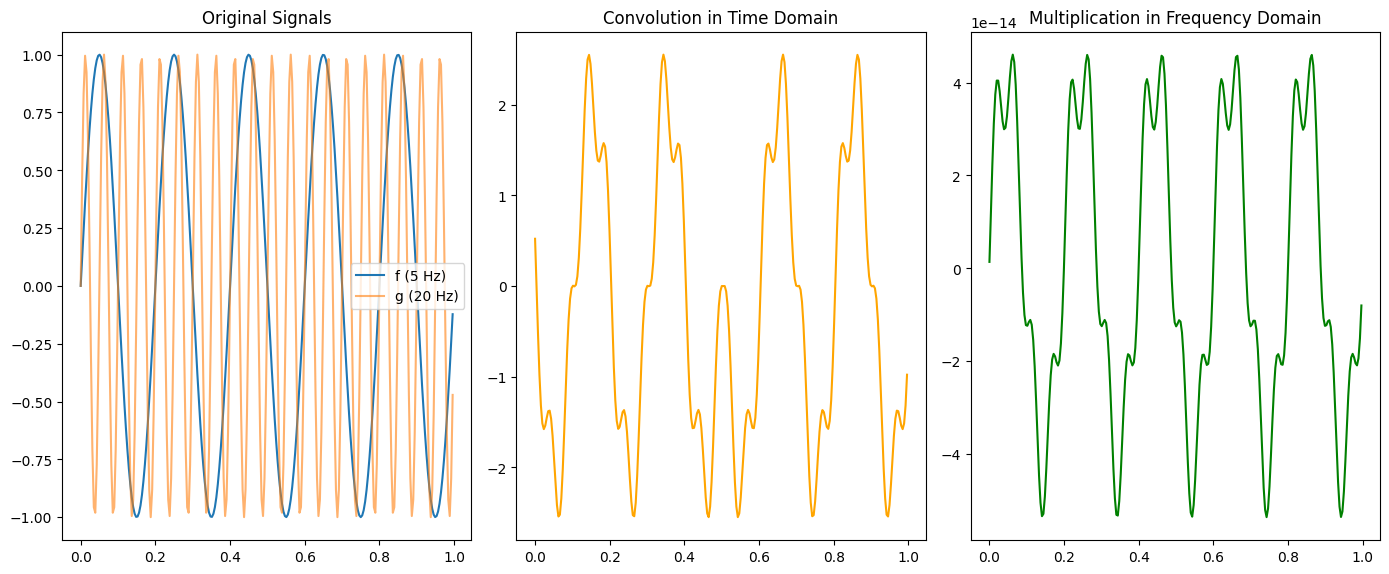

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, ifft

# Create two signals
t = np.linspace(0, 1, 256, endpoint=False)
f = np.sin(2 * np.pi * 5 * t)          # 5 Hz sine wave
g = np.sin(2 * np.pi * 20 * t)         # 20 Hz sine wave

# Time-domain convolution
conv_time = np.convolve(f, g, mode='same')

# Frequency-domain convolution via multiplication of FFTs
F = fft(f)
G = fft(g)
conv_freq = ifft(F * G).real  # Taking real part of inverse FFT

# Plotting
plt.figure(figsize=(14, 6))

plt.subplot(1, 3, 1)
plt.plot(t, f, label='f (5 Hz)')
plt.plot(t, g, label='g (20 Hz)', alpha=0.6)
plt.title("Original Signals")
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(t, conv_time, color='orange')
plt.title("Convolution in Time Domain")

plt.subplot(1, 3, 3)
plt.plot(t, conv_freq, color='green')
plt.title("Multiplication in Frequency Domain")

plt.tight_layout()
plt.show()


`Conv2D` from `keras` is an implementation of a convolution learner- that learns the values required in a kernel, from random initializations.
These kernels are:

* Randomly initialized (using an initializer like `glorot_uniform` or `he_normal` by default).

* Learned via backpropagation: During training, gradient descent updates the kernel weights based on how well the current feature maps help minimize the loss.

* The process is data-driven — the model discovers patterns like edges, corners, and eventually abstract concepts just by optimizing the weights in these kernels.

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


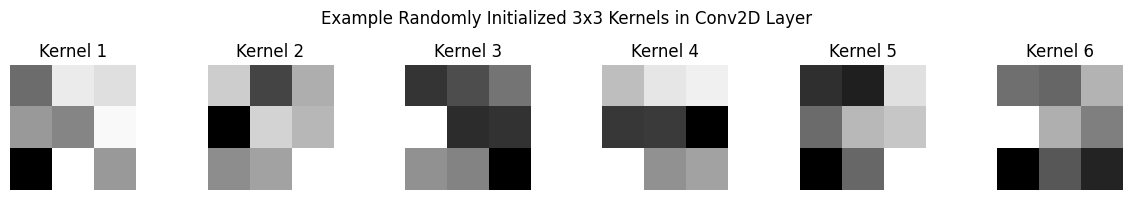

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.initializers import RandomNormal

# Create a dummy model with one Conv2D layer
model = Sequential([
    Conv2D(6, (3, 3), input_shape=(28, 28, 1), kernel_initializer=RandomNormal(mean=0.0, stddev=1.0))
])

# Extract kernel weights
kernels = model.layers[0].get_weights()[0]  # shape: (3, 3, 1, 6)

# Plot each 3x3 kernel
plt.figure(figsize=(12, 2))
for i in range(kernels.shape[-1]):
    kernel = kernels[:, :, 0, i]  # Get 2D slice for filter i
    plt.subplot(1, 6, i + 1)
    plt.imshow(kernel, cmap='gray')
    plt.title(f'Kernel {i+1}')
    plt.axis('off')

plt.suptitle("Example Randomly Initialized 3x3 Kernels in Conv2D Layer")
plt.tight_layout()
plt.show()


Now lets do an example with the MNIST dataset...

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Layer

class FFTLayer(Layer):
    def __init__(self, **kwargs):
        super(FFTLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        height, width = input_shape[1], input_shape[2]

        # Real and imaginary parts of learnable frequency mask
        self.freq_mask_real = self.add_weight(
            shape=(height, width),
            initializer='glorot_uniform',
            trainable=True,
            name='freq_mask_real'
        )
        self.freq_mask_imag = self.add_weight(
            shape=(height, width),
            initializer='zeros',
            trainable=True,
            name='freq_mask_imag'
        )

    def call(self, inputs):
        # Remove channel dim (assumes grayscale input)
        x = tf.squeeze(inputs, axis=-1)  # shape: (batch, height, width)
        x_complex = tf.cast(x, tf.complex64)

        # Apply FFT
        x_fft = tf.signal.fft2d(x_complex)

        # Construct complex mask and apply it
        mask = tf.complex(self.freq_mask_real, self.freq_mask_imag)
        x_filtered = x_fft * mask

        # Inverse FFT
        x_ifft = tf.signal.ifft2d(x_filtered)
        x_abs = tf.math.abs(x_ifft)

        # Add channel dim back
        return tf.expand_dims(x_abs, axis=-1)  # shape: (batch, height, width, 1)

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Preprocess: reshape and normalize
x_train = x_train.reshape((-1, 28, 28, 1)).astype("float32") / 255.0
x_test = x_test.reshape((-1, 28, 28, 1)).astype("float32") / 255.0

# One-hot encode the labels
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Build a simple CNN
conv_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

# Compile the model
conv_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
conv_history = conv_model.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.1)

# Evaluate on test set
test_loss, test_acc = conv_model.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")

## Build a FFT based model
# Build model
fft_model = Sequential([
    FFTLayer(input_shape=(28, 28, 1)),  # input_shape goes here
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

fft_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
fft_history = fft_model.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.1)

# Evaluate on test set
fft_test_loss, fft_test_acc = fft_model.evaluate(x_test, y_test)
print(f"Test Accuracy: {fft_test_acc:.4f}")

Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 51ms/step - accuracy: 0.8530 - loss: 0.5097 - val_accuracy: 0.9748 - val_loss: 0.0955
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 22s 52ms/step - accuracy: 0.9725 - loss: 0.0927 - val_accuracy: 0.9835 - val_loss: 0.0660
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 50ms/step - accuracy: 0.9834 - loss: 0.0589 - val_accuracy: 0.9860 - val_loss: 0.0550
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9770 - loss: 0.0630
Test Accuracy: 0.9833


<ipython-input-34-abc33d042662>:12: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(FFTLayer, self).__init__(**kwargs)


Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6315 - loss: 1.3909 - val_accuracy: 0.9302 - val_loss: 0.2621
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.9146 - loss: 0.2982 - val_accuracy: 0.9503 - val_loss: 0.1859
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9379 - loss: 0.2151 - val_accuracy: 0.9570 - val_loss: 0.1558
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9337 - loss: 0.2096
Test Accuracy: 0.9434


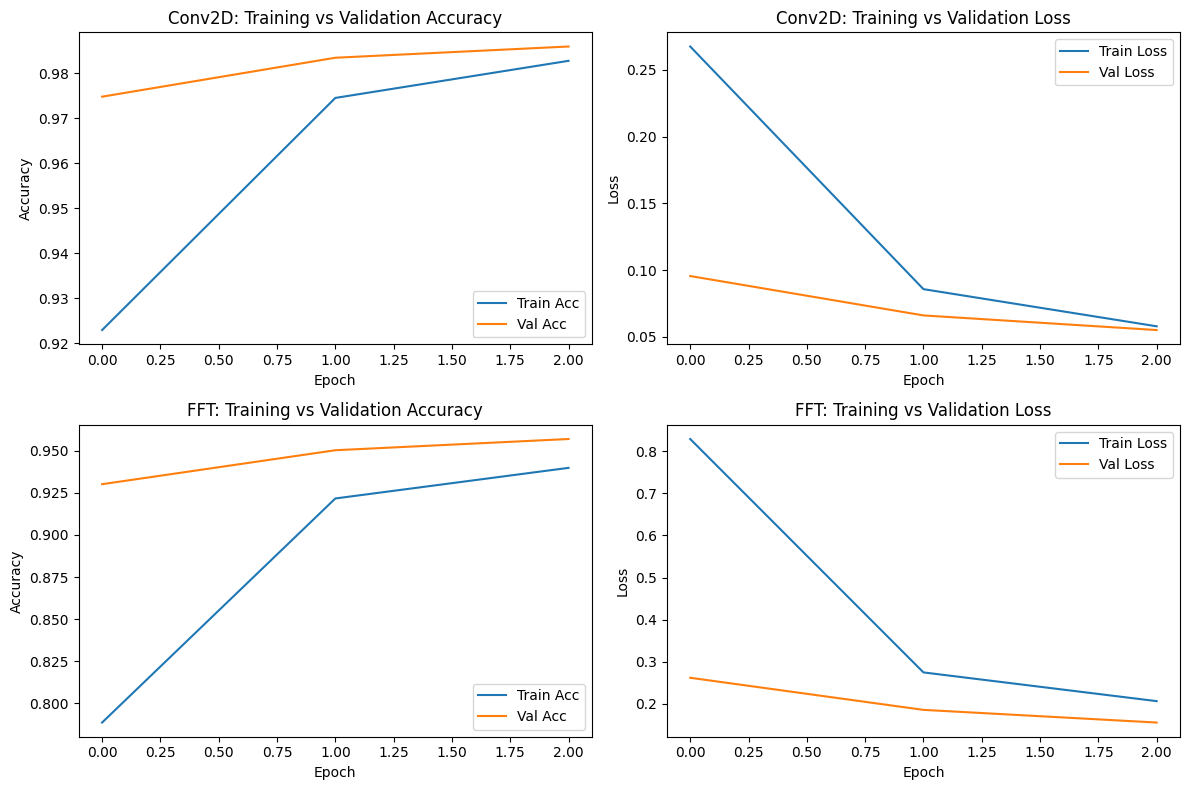

In [ ]:
# Plot results side by side in 2x2 layout
plt.figure(figsize=(12, 8))

# Conv2D Accuracy
plt.subplot(2, 2, 1)
plt.plot(conv_history.history['accuracy'], label='Train Acc')
plt.plot(conv_history.history['val_accuracy'], label='Val Acc')
plt.title("Conv2D: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Conv2D Loss
plt.subplot(2, 2, 2)
plt.plot(conv_history.history['loss'], label='Train Loss')
plt.plot(conv_history.history['val_loss'], label='Val Loss')
plt.title("Conv2D: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# FFT Accuracy
plt.subplot(2, 2, 3)
plt.plot(fft_history.history['accuracy'], label='Train Acc')
plt.plot(fft_history.history['val_accuracy'], label='Val Acc')
plt.title("FFT: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# FFT Loss
plt.subplot(2, 2, 4)
plt.plot(fft_history.history['loss'], label='Train Loss')
plt.plot(fft_history.history['val_loss'], label='Val Loss')
plt.title("FFT: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
kernels = conv_model.layers[0].get_weights()[0]
print(kernels.shape)

(3, 3, 1, 32)


In [ ]:
print("✅ Final Validation Accuracy (Conv2D):", conv_history.history['val_accuracy'][-1])
print("✅ Final Validation Accuracy (FFT):", fft_history.history['val_accuracy'][-1])

print("❌ Final Validation Loss (Conv2D):", conv_history.history['val_loss'][-1])
print("❌ Final Validation Loss (FFT):", fft_history.history['val_loss'][-1])


✅ Final Validation Accuracy (Conv2D): 0.9860000014305115
✅ Final Validation Accuracy (FFT): 0.9570000171661377
❌ Final Validation Loss (Conv2D): 0.05498334765434265
❌ Final Validation Loss (FFT): 0.15576259791851044


## **Fourier Domain Learning Instead of Convolution**

The side by side comparison shows that Conv2D is performing slightly better than the FFT layer- however, the loss curves same very much the same shape. (Perhaps a few more epochs can improve the output accuracy for the fft?- **10 Bonus points for trying**)

1. Applying FFT to the images would converts the data to frequency domain.
2. Multiply by a learnable complex-valued mask or filter (like a kernel) would apply the shifts.
3. Apply IFFT (inverse FFT) to get back to the spatial domain would allow the solution generation.

Objective function will be the kernel shape and values.

Output will be similar to a convolved feature map — but learned in frequency space.

Now lets see an example of why fft does with simulated data.

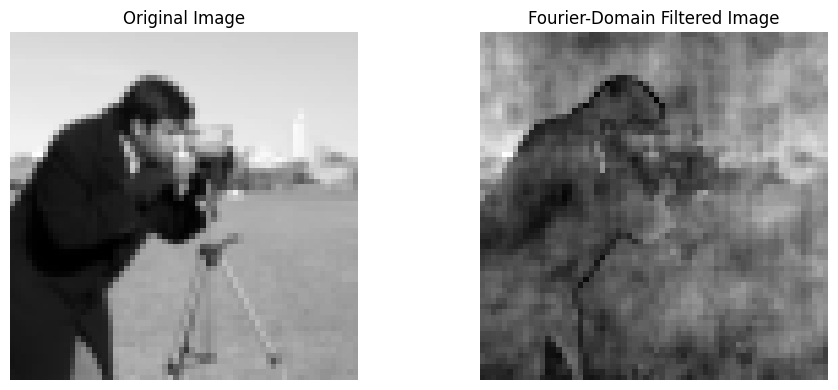

In [ ]:
## Example with a simulated image

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift
from skimage.data import camera
from skimage.transform import resize

# Simulate a grayscale image
img = resize(camera(), (64, 64), anti_aliasing=True)

# Step 1: Fourier Transform of the image
img_fft = fft2(img)

# Step 2: Learnable filter (simulate with random frequency mask)
np.random.seed(42)
freq_mask = np.random.rand(*img.shape) + 1j * np.random.rand(*img.shape)

# Step 3: Apply frequency-domain "filter"
filtered_fft = img_fft * freq_mask

# Step 4: Inverse FFT to get filtered image
filtered_img = np.abs(ifft2(filtered_fft))

# Plot original and filtered image
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(filtered_img, cmap='gray')
plt.title("Fourier-Domain Filtered Image")
plt.axis('off')

plt.tight_layout()
plt.show()


In a typical Fourier-domain approach, if we replace `Conv2D` with a frequency-based operation, then the "learned kernels" would correspond to complex-valued frequency masks that modify the magnitude and phase of specific frequencies.

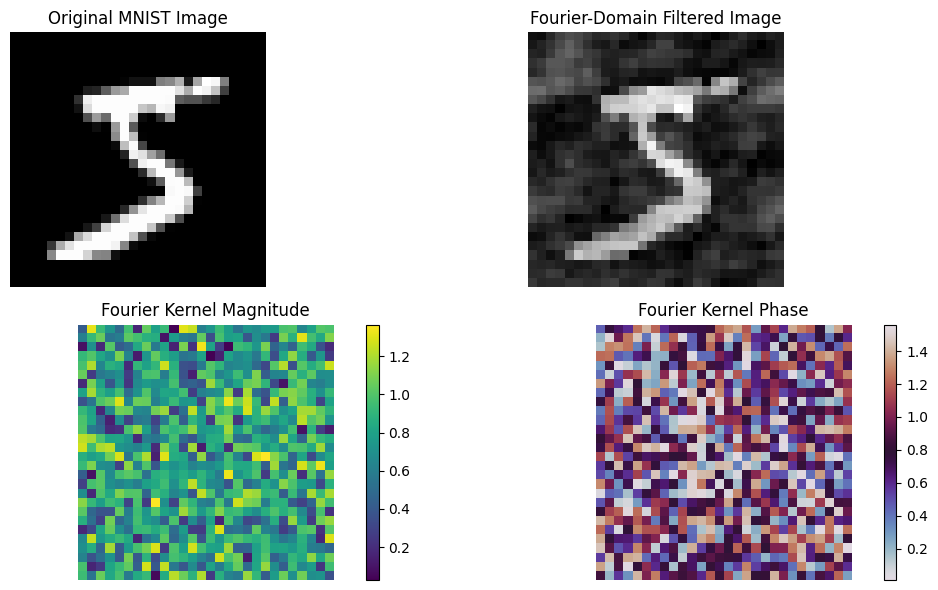

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2

# Load MNIST data and select a sample image
(x_train, y_train), _ = mnist.load_data()
x_sample = x_train[0].astype(np.float32) / 255.0  # Normalize image

# Step 1: Fourier Transform of the image
img_fft = fft2(x_sample)

# Step 2: Simulate a learnable complex-valued frequency kernel
np.random.seed(42)
freq_kernel = np.random.rand(*x_sample.shape) + 1j * np.random.rand(*x_sample.shape)

# Save kernel details for later inspection
kernel_magnitude = np.abs(freq_kernel)
kernel_phase = np.angle(freq_kernel)

# Step 3: Apply the frequency-domain kernel
filtered_fft = img_fft * freq_kernel

# Step 4: Inverse FFT to get back the spatial-domain output
filtered_img = np.abs(ifft2(filtered_fft))

# Plot original image, filtered image, and the kernel (magnitude + phase)
plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
plt.imshow(x_sample, cmap='gray')
plt.title("Original MNIST Image")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(filtered_img, cmap='gray')
plt.title("Fourier-Domain Filtered Image")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(kernel_magnitude, cmap='viridis')
plt.title("Fourier Kernel Magnitude")
plt.colorbar()
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(kernel_phase, cmap='twilight')
plt.title("Fourier Kernel Phase")
plt.colorbar()
plt.axis('off')

plt.tight_layout()
plt.show()


Now- lets see a spatial example...
We will first generate synthetic data like we did for spatial patterning previously in the Spatial modeling discussion- and then followup with Modeling procedure for Spatial analytics.
1) Synthesizes spatial yield patterns on a field grid,
2) Trains a tiny CNN to learn feature maps that explain those patterns,
3) Extracts and visualizes learned kernels next to classical spatial contiguity kernels (rook & queen),
4) Computes similarity metrics between learned kernels and contiguity kernels.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
torch.__version__

'2.8.0+cu126'

## 1) Generate Synthetic Spatial Yield Patterns
We construct a square field grid and blend multiple latent components:
- **Global trend** (smooth gradient)
- **Row/striping** (e.g., planter passes)
- **Localized blobs** (e.g., disease patches, soil texture zones)
- **Small-scale noise** (measurement/error)

The target we try to **predict** is a (possibly non-linear) combination of these components.

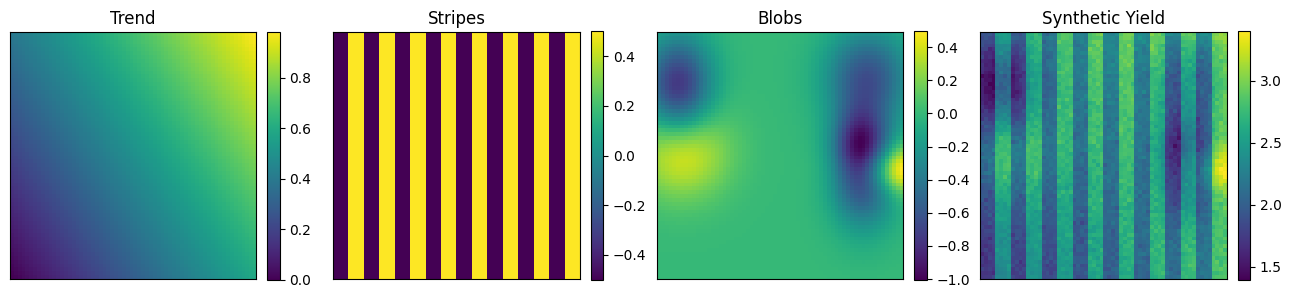

In [ ]:
rng = np.random.default_rng(42)
GRID = 64  # side length of the field grid
y, x = np.mgrid[0:GRID, 0:GRID]

# 1) Smooth global trend
trend = 0.6 * (x/GRID) + 0.4 * (y/GRID)

# 2) Planter-like striping (row effects)
stripe_width = 4
stripes = ((x // stripe_width) % 2).astype(float)
stripes = (stripes - stripes.mean())

# 3) Localized Gaussian blobs
def gaussian_blob(cx, cy, sx, sy, amp):
    return amp * np.exp(-(((x-cx)**2)/(2*sx**2) + ((y-cy)**2)/(2*sy**2)))

num_blobs = 6
blobs = np.zeros_like(trend)
for _ in range(num_blobs):
    cx, cy = rng.integers(0, GRID, size=2)
    sx, sy = rng.uniform(3, 10, size=2)
    amp = rng.uniform(0.4, 1.0) * rng.choice([-1, 1])
    blobs += gaussian_blob(cx, cy, sx, sy, amp)

# 4) Noise
noise = rng.normal(0, 0.05, size=(GRID, GRID))

# Compose a synthetic yield surface (bounded and shifted)
yield_surface = 2.0 + 0.9*trend + 0.6*stripes + 0.8*blobs + noise

fig, axs = plt.subplots(1, 4, figsize=(16,4))
for ax, im, title in zip(
    axs,
    [trend, stripes, blobs, yield_surface],
    ["Trend", "Stripes", "Blobs", "Synthetic Yield"],
):
    m = ax.imshow(im, origin='lower')
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(m, ax=ax, fraction=0.046, pad=0.04)
plt.show()

## 2) Spatial Contiguity Kernels: Rook vs Queen
We'll use simple 3×3 stencils:
- **Rook (4-neighbor):** neighbors up/down/left/right.
- **Queen (8-neighbor):** all surrounding neighbors.

We also include a **mean (box) filter** and a **Laplacian** for reference.

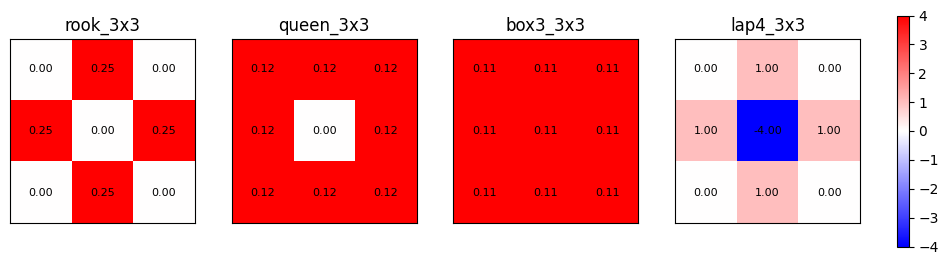

In [ ]:
import numpy as np

rook = np.array([[0,1,0],[1,0,1],[0,1,0]], dtype=float)
rook = rook / rook.sum()

queen = np.ones((3,3), dtype=float)
queen[1,1] = 0
queen = queen / queen.sum()

box3 = np.ones((3,3), dtype=float) / 9.0

# Discrete Laplacian (4-neighbor variant)
lap4 = np.array([[0,1,0],[1,-4,1],[0,1,0]], dtype=float)

kernels = {
    'rook_3x3': rook,
    'queen_3x3': queen,
    'box3_3x3': box3,
    'lap4_3x3': lap4
}

fig, axs = plt.subplots(1, len(kernels), figsize=(12,3))
for ax, (name, K) in zip(axs, kernels.items()):
    im = ax.imshow(K, cmap='bwr', vmin=-np.abs(K).max(), vmax=np.abs(K).max())
    ax.set_title(name)
    for (i,j), v in np.ndenumerate(K):
        ax.text(j, i, f"{v:.2f}", ha='center', va='center', fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axs.ravel().tolist(), fraction=0.046, pad=0.04)
plt.show()

## 3) Prepare Data for CNN
We create small patches sampled across the field, with the **target** being the central pixel's yield. The CNN learns local filters that best predict the center from its neighborhood (akin to learning spatial autocorrelation cues).

In [ ]:
def extract_patches(img, patch=9, stride=2):
    pad = patch//2
    padded = np.pad(img, pad, mode='reflect')
    H, W = img.shape
    xs, ys, Xs, ys_center = [], [], [], []
    for i in range(0, H, stride):
        for j in range(0, W, stride):
            pi, pj = i+pad, j+pad
            patch_ij = padded[pi-pad:pi+pad+1, pj-pad:pj+pad+1]
            Xs.append(patch_ij)
            ys_center.append(img[i,j])
    X = np.stack(Xs, 0).astype('float32')[:, None, :, :]  # [N, 1, P, P]
    y = np.array(ys_center, dtype='float32')[:, None]
    return X, y

PATCH = 9
STRIDE = 2
X, y = extract_patches(yield_surface, patch=PATCH, stride=STRIDE)
X.shape, y.shape

((1024, 1, 9, 9), (1024, 1))

## 4) Tiny CNN Regressor
A minimal CNN: **Conv2d(1→K, 3×3)** → ReLU → **1×1 conv** → global average pooling → linear output.
The first 3×3 conv kernels will be inspected and compared to rook/queen.

In [ ]:
class TinyCNN(nn.Module):
    def __init__(self, K=6):
        super().__init__()
        self.conv = nn.Conv2d(1, K, kernel_size=3, padding=0, bias=False)
        self.head = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.Conv2d(K, 1, kernel_size=1, bias=True)
        )
        self.pool = nn.AdaptiveAvgPool2d((1,1))

    def forward(self, x):  # x: [B,1,P,P]
        h = self.conv(x)           # [B,K,P-2,P-2]
        h = self.head(h)           # [B,1,P-2,P-2]
        h = self.pool(h).squeeze(-1).squeeze(-1)  # [B,1]
        return h

K = 6  # number of learned 3x3 filters
model = TinyCNN(K=K)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

X_t = torch.from_numpy(X).to(device)
y_t = torch.from_numpy(y).to(device)

ds = TensorDataset(X_t, y_t)
dl = DataLoader(ds, batch_size=256, shuffle=True)

opt = optim.Adam(model.parameters(), lr=1e-2)
loss_fn = nn.MSELoss()

for epoch in range(50):
    total = 0.0
    for xb, yb in dl:
        opt.zero_grad()
        pred = model(xb)
        loss = loss_fn(pred, yb.squeeze(1))
        loss.backward()
        opt.step()
        total += loss.item()*xb.size(0)
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1:02d} | MSE: {total/len(ds):.6f}")

# Pull learned 3x3 kernels (shape: [K,1,3,3])
with torch.no_grad():
    learned = model.conv.weight.cpu().numpy()[:,0,:,:]
learned.shape

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/loss.py:616: UserWarning: Using a target size (torch.Size([256])) that is different to the input size (torch.Size([256, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Epoch 10 | MSE: 0.223027
Epoch 20 | MSE: 0.188399
Epoch 30 | MSE: 0.186914
Epoch 40 | MSE: 0.185865
Epoch 50 | MSE: 0.185835


(6, 3, 3)

5) Visualize Learned vs Rook/Queen
We show all learned 3×3 filters and place rook/queen next to the closest learned filters (by cosine similarity).

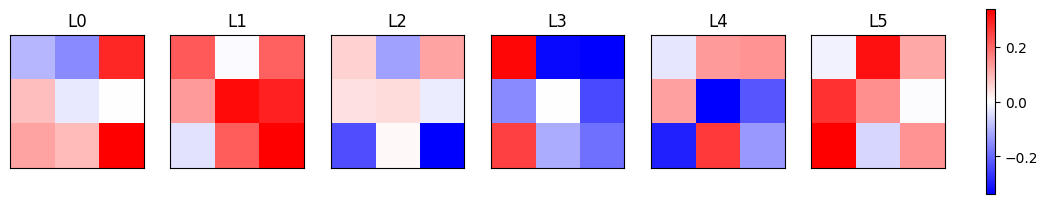

Cosine similarities to rook: [ 0.022  0.467 -0.108 -0.573  0.237  0.45 ]
Cosine similarities to queen: [ 0.466  0.708 -0.379 -0.379 -0.013  0.666]
Best match to rook: L1
Best match to queen: L1


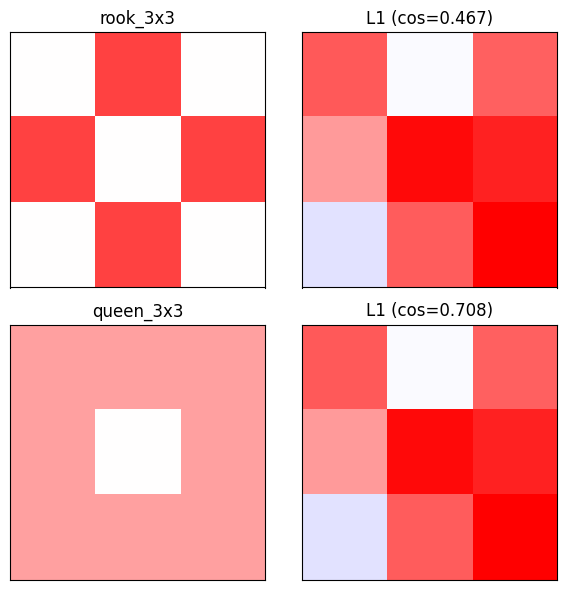

In [ ]:
from numpy.linalg import norm

def cosine_sim(A, B):
    a = A.reshape(-1)
    b = B.reshape(-1)
    na = norm(a)+1e-12
    nb = norm(b)+1e-12
    return float((a@b)/(na*nb))

# visualize learned filters
cols = K
fig, axs = plt.subplots(1, cols, figsize=(2.2*cols, 2.4))
for i in range(K):
    ax = axs[i]
    L = learned[i]
    im = ax.imshow(L, cmap='bwr', vmin=-np.abs(L).max(), vmax=np.abs(L).max())
    ax.set_title(f"L{i}")
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axs.ravel().tolist(), fraction=0.046, pad=0.04)
plt.show()

# compute similarities to rook/queen
sims = {
    'rook': [cosine_sim(learned[i], kernels['rook_3x3']) for i in range(K)],
    'queen': [cosine_sim(learned[i], kernels['queen_3x3']) for i in range(K)],
}
best_rook = int(np.argmax(sims['rook']))
best_queen = int(np.argmax(sims['queen']))
print("Cosine similarities to rook:", np.round(sims['rook'],3))
print("Cosine similarities to queen:", np.round(sims['queen'],3))
print(f"Best match to rook: L{best_rook}")
print(f"Best match to queen: L{best_queen}")

fig, axs = plt.subplots(2, 2, figsize=(6,6))
pairs = [("rook_3x3", best_rook), ("queen_3x3", best_queen)]
for r,(name, idx) in enumerate(pairs):
    ax1, ax2 = axs[r,0], axs[r,1]
    target = kernels[name]
    learnedK = learned[idx]
    v = max(np.abs(target).max(), np.abs(learnedK).max())
    im1 = ax1.imshow(target, cmap='bwr', vmin=-v, vmax=v)
    im2 = ax2.imshow(learnedK, cmap='bwr', vmin=-v, vmax=v)
    ax1.set_title(f"{name}")
    ax2.set_title(f"L{idx} (cos={cosine_sim(learnedK, target):.3f})")
    for ax in (ax1, ax2):
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## 6) (Optional) Apply Filters to the Field
Compare the **response maps** produced by learned vs. rook/queen kernels when convolved over the field.

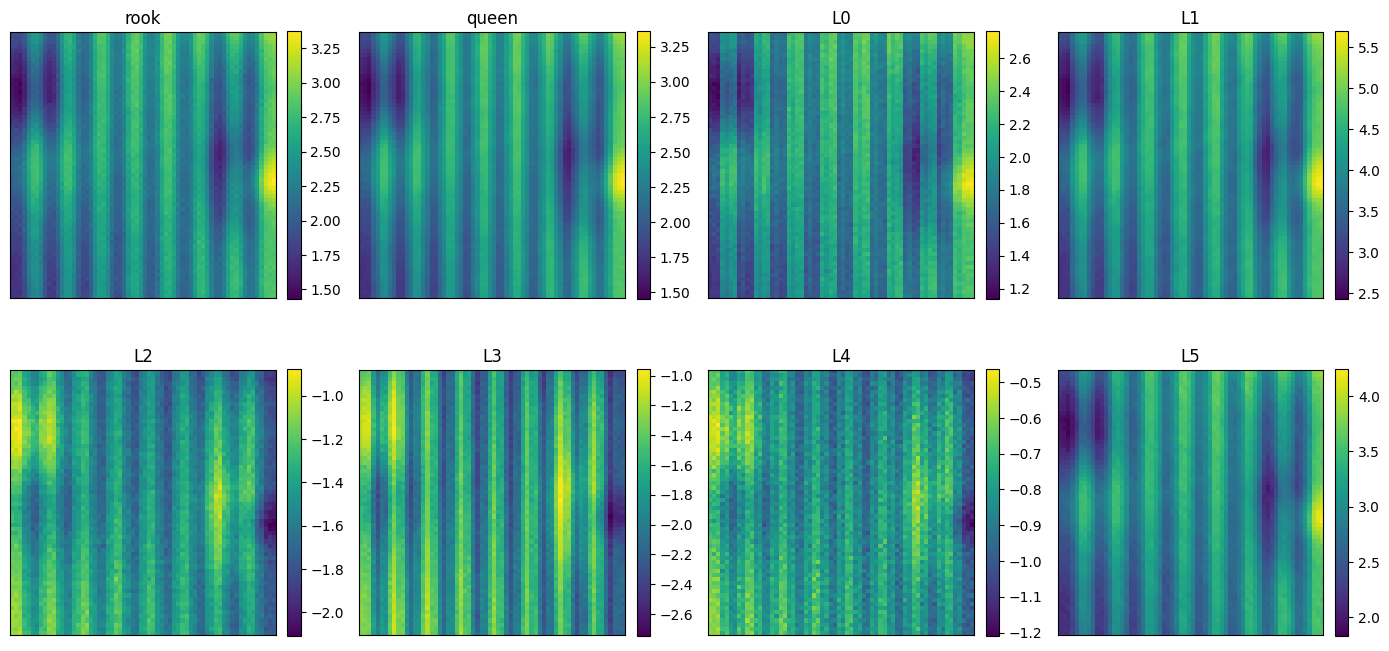

In [ ]:
import scipy.signal as sig

def conv2(img, K):
    return sig.convolve2d(img, K[::-1, ::-1], mode='same', boundary='symm')

maps = {}
maps['rook'] = conv2(yield_surface, kernels['rook_3x3'])
maps['queen'] = conv2(yield_surface, kernels['queen_3x3'])
for i in range(K):
    maps[f'L{i}'] = conv2(yield_surface, learned[i])

fig, axs = plt.subplots(2, 4, figsize=(14,7))
names = ['rook','queen'] + [f'L{i}' for i in range(min(6,K))]
for ax, name in zip(axs.ravel(), names[:8]):
    m = ax.imshow(maps[name], origin='lower')
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(m, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

## 7) Similarity Metrics
- **Cosine similarity** & **Pearson correlation** between vectorized kernels.
- Rank learned kernels by similarity to rook/queen.

In [ ]:
def corrcoef(a,b):
    a = a.reshape(-1)
    b = b.reshape(-1)
    if a.std()==0 or b.std()==0:
        return 0.0
    return float(np.corrcoef(a,b)[0,1])

def rank_sims(target_name):
    target = kernels[target_name]
    rows = []
    for i in range(K):
        c = cosine_sim(learned[i], target)
        r = corrcoef(learned[i], target)
        rows.append((i, c, r))
    rows.sort(key=lambda t: (-t[1], -t[2]))
    return rows

for name in ['rook_3x3','queen_3x3']:
    rows = rank_sims(name)
    print(f"\nTop matches to {name} (by cosine, then corr):")
    for i,(idx,c,r) in enumerate(rows[:5],1):
        print(f" {i}. L{idx}  cos={c:.3f}  corr={r:.3f}")


Top matches to rook_3x3 (by cosine, then corr):
 1. L1  cos=0.467  corr=-0.201
 2. L5  cos=0.450  corr=-0.047
 3. L4  cos=0.237  corr=0.500
 4. L0  cos=0.022  corr=-0.381
 5. L2  cos=-0.108  corr=0.152

Top matches to queen_3x3 (by cosine, then corr):
 1. L1  cos=0.708  corr=-0.378
 2. L5  cos=0.666  corr=-0.025
 3. L0  cos=0.466  corr=0.234
 4. L4  cos=-0.013  corr=0.514
 5. L2  cos=-0.379  corr=-0.237


# Modeling Spatial Variability: CNN vs Rook/Queen & Graph Laplacian

**Objective.** Simulate a field yield surface; learn local patterns with a CNN; build Rook/Queen spatial contiguity and a Laplacian smoother; then compare **prediction accuracy** and **variance components** side-by-side. Also compare **learned CNN kernels** to **Rook/Queen** stencils.

In [ ]:
# ============= Configuration =============
GRID_NROWS = 40
GRID_NCOLS = 40
RANDOM_SEED = 42
TRAIN_FRAC = 0.7
LAMBDA_LAPL = 1.0   # smoothing strength for Laplacian model

import sys, subprocess, importlib
def ensure(pkg, pip_name=None):
    pip_name = pip_name or pkg
    try:
        importlib.import_module(pkg)
    except Exception:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name])

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from numpy.linalg import norm
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
rng = np.random.default_rng(RANDOM_SEED)

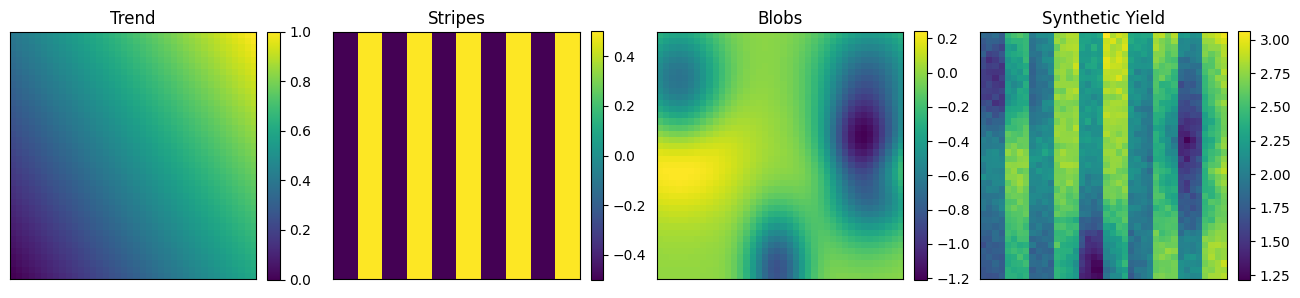

In [ ]:
nr, nc = GRID_NROWS, GRID_NCOLS
ygrid, xgrid = np.mgrid[0:nr, 0:nc]

# Components
trend = 0.6*(xgrid/(nc-1)) + 0.4*(ygrid/(nr-1))
stripe_w = 4
stripes = ((xgrid // stripe_w) % 2).astype(float)
stripes = (stripes - stripes.mean())

def gaussian_blob(cx, cy, sx, sy, amp):
    return amp * np.exp(-(((xgrid-cx)**2)/(2*sx**2) + ((ygrid-cy)**2)/(2*sy**2)))

num_blobs = 8
blobs = np.zeros_like(trend)
for _ in range(num_blobs):
    cx, cy = rng.integers(0, nc), rng.integers(0, nr)
    sx, sy = float(rng.uniform(2.5, 8.0)), float(rng.uniform(2.5, 8.0))
    amp = float(rng.uniform(0.4, 1.0)) * float(rng.choice([-1, 1]))
    blobs += gaussian_blob(cx, cy, sx, sy, amp)

noise = rng.normal(0, 0.05, size=(nr, nc))

yield_surface = 2.0 + 0.9*trend + 0.6*stripes + 0.8*blobs + noise

fig, axs = plt.subplots(1, 4, figsize=(16,4))
for ax, im, title in zip(
    axs,
    [trend, stripes, blobs, yield_surface],
    ["Trend", "Stripes", "Blobs", "Synthetic Yield"],
):
    m = ax.imshow(im, origin='lower')
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(m, ax=ax, fraction=0.046, pad=0.04)
plt.show()


In [ ]:
def grid_index(r, c, nc):
    return r*nc + c

def build_adjacency(nr, nc, mode='rook'):
    rows, cols, data = [], [], []
    for r in range(nr):
        for c in range(nc):
            i = grid_index(r,c,nc)
            nbrs = []
            for dr, dc in [(1,0),(-1,0),(0,1),(0,-1)]:
                rr, cc = r+dr, c+dc
                if 0 <= rr < nr and 0 <= cc < nc:
                    nbrs.append(grid_index(rr,cc,nc))
            if mode == 'queen':
                for dr in (-1,0,1):
                    for dc in (-1,0,1):
                        if dr==0 and dc==0: continue
                        rr, cc = r+dr, c+dc
                        if 0 <= rr < nr and 0 <= cc < nc:
                            j = grid_index(rr,cc,nc)
                            if j not in nbrs:
                                nbrs.append(j)
            for j in nbrs:
                rows.append(i); cols.append(j); data.append(1.0)
    N = nr*nc
    import scipy.sparse as sp
    A = sp.coo_matrix((data, (rows, cols)), shape=(N,N)).tocsr()
    return A

A_rook  = build_adjacency(nr, nc, 'rook')
A_queen = build_adjacency(nr, nc, 'queen')
D_rook  = sp.diags(A_rook.sum(axis=1).A1)
D_queen = sp.diags(A_queen.sum(axis=1).A1)
L_rook  = D_rook - A_rook
L_queen = D_queen - A_queen
print(A_rook.shape, A_queen.shape)

(1600, 1600) (1600, 1600)


In [ ]:
yvec = yield_surface.reshape(-1)
N = yvec.size
mask = rng.random(N) < TRAIN_FRAC
W = sp.diags(mask.astype(float))

def lap_smooth(L, y, W, lam):
    M = W + lam*L
    rhs = W @ y
    yhat = spla.spsolve(M.tocsc(), rhs)
    return yhat

yhat_rook  = lap_smooth(L_rook,  yvec, W, LAMBDA_LAPL)
yhat_queen = lap_smooth(L_queen, yvec, W, LAMBDA_LAPL)

def metrics(y_true, y_pred, test_mask):
    r = y_true[test_mask] - y_pred[test_mask]
    mse = float(np.mean(r**2))
    mae = float(np.mean(np.abs(r)))
    ss_res = float(np.sum(r**2))
    ss_tot = float(np.sum((y_true[test_mask]-np.mean(y_true[test_mask]))**2))
    r2 = 1 - ss_res/ss_tot if ss_tot>0 else 0.0
    return mse, mae, r2

test_mask = ~mask
m_rook  = metrics(yvec, yhat_rook,  test_mask)
m_queen = metrics(yvec, yhat_queen, test_mask)
print("Laplacian smoother metrics (MSE, MAE, R2):")
print(" Rook :", np.round(m_rook,3))
print(" Queen:", np.round(m_queen,3))


Laplacian smoother metrics (MSE, MAE, R2):
 Rook : [0.043 0.189 0.715]
 Queen: [0.068 0.246 0.544]


In [ ]:
from scipy.signal import convolve2d
rook3 = np.array([[0,1,0],[1,0,1],[0,1,0]], float)
rook3 = rook3/rook3.sum()
queen3 = np.ones((3,3), float); queen3[1,1]=0; queen3 = queen3/queen3.sum()

def conv_pred(yield_img, K):
    resp = convolve2d(yield_img, K[::-1, ::-1], mode='same', boundary='symm')
    return resp

resp_rook3  = conv_pred(yield_surface, rook3).reshape(-1)
resp_queen3 = conv_pred(yield_surface, queen3).reshape(-1)

def fit_affine(resp, y, train_mask):
    X = np.vstack([resp[train_mask], np.ones(train_mask.sum())]).T
    w, *_ = np.linalg.lstsq(X, y[train_mask], rcond=None)
    a,b = w
    return a,b

a_r,b_r = fit_affine(resp_rook3, yvec, mask)
a_q,b_q = fit_affine(resp_queen3, yvec, mask)
yhat_r3 = a_r*resp_rook3 + b_r
yhat_q3 = a_q*resp_queen3 + b_q

def metrics_vec(y_true, y_pred, test_mask):
    r = y_true[test_mask] - y_pred[test_mask]
    mse = float(np.mean(r**2))
    mae = float(np.mean(np.abs(r)))
    ss_res = float(np.sum(r**2))
    ss_tot = float(np.sum((y_true[test_mask]-np.mean(y_true[test_mask]))**2))
    r2 = 1 - ss_res/ss_tot if ss_tot>0 else 0.0
    return mse, mae, r2

m_r3 = metrics_vec(yvec, yhat_r3, test_mask)
m_q3 = metrics_vec(yvec, yhat_q3, test_mask)
print("3x3-kernel models (MSE, MAE, R2):")
print(" Rook-3x3 :", np.round(m_r3,3))
print(" Queen-3x3:", np.round(m_q3,3))

3x3-kernel models (MSE, MAE, R2):
 Rook-3x3 : [0.012 0.091 0.917]
 Queen-3x3: [0.026 0.127 0.828]


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/loss.py:616: UserWarning: Using a target size (torch.Size([512])) that is different to the input size (torch.Size([512, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/loss.py:616: UserWarning: Using a target size (torch.Size([96])) that is different to the input size (torch.Size([96, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Epoch 10 train MSE=0.185057
Epoch 20 train MSE=0.181386
Epoch 30 train MSE=0.180609
CNN metrics (MSE, MAE, R2): [0.079 0.265 0.482]


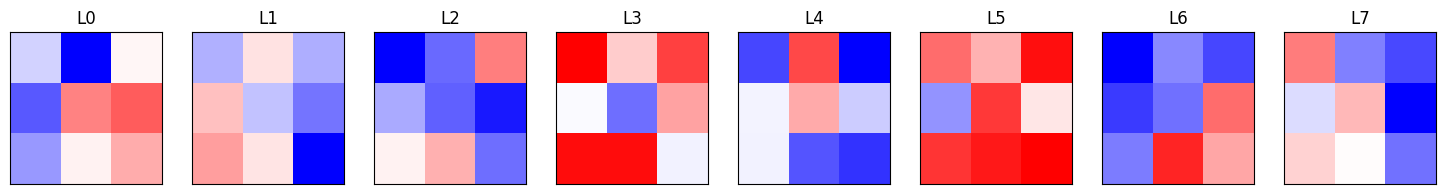

In [ ]:
def extract_patches(img, patch=9):
    pad = patch//2
    padded = np.pad(img, pad, mode='reflect')
    H, W = img.shape
    Xs, ys = [], []
    for i in range(H):
        for j in range(W):
            pi, pj = i+pad, j+pad
            patch_ij = padded[pi-pad:pi+pad+1, pj-pad:pj+pad+1]
            Xs.append(patch_ij)
            ys.append(img[i,j])
    X = np.stack(Xs, 0).astype('float32')[:,None,:,:]
    y = np.array(ys, dtype='float32')[:,None]
    return X, y

X_img, y_img = extract_patches(yield_surface, patch=9)
idx = np.arange(X_img.shape[0]); np.random.shuffle(idx)
cut = int(TRAIN_FRAC*len(idx))
idx_train, idx_test = idx[:cut], idx[cut:]

class TinyCNN(nn.Module):
    def __init__(self, K=8):
        super().__init__()
        self.conv = nn.Conv2d(1, K, kernel_size=3, padding=0, bias=False)
        self.head = nn.Sequential(nn.ReLU(inplace=True), nn.Conv2d(K,1,kernel_size=1,bias=True))
        self.pool = nn.AdaptiveAvgPool2d((1,1))
    def forward(self, x):
        h = self.conv(x); h = self.head(h); h = self.pool(h).squeeze(-1).squeeze(-1)
        return h

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = TinyCNN(K=8).to(device)
X_t = torch.from_numpy(X_img).to(device)
y_t = torch.from_numpy(y_img).to(device)
ds_train = TensorDataset(X_t[idx_train], y_t[idx_train])
ds_test  = TensorDataset(X_t[idx_test],  y_t[idx_test])
dl_train = DataLoader(ds_train, batch_size=512, shuffle=True)
dl_test  = DataLoader(ds_test,  batch_size=1024)

opt = optim.Adam(model.parameters(), lr=1e-2)
loss_fn = nn.MSELoss()
for epoch in range(30):
    model.train(); tot=0
    for xb,yb in dl_train:
        opt.zero_grad(); pred = model(xb); loss = loss_fn(pred, yb.squeeze(1))
        loss.backward(); opt.step(); tot += loss.item()*xb.size(0)
    if (epoch+1)%10==0:
        print(f"Epoch {epoch+1:02d} train MSE={tot/len(ds_train):.6f}")

model.eval();
with torch.no_grad():
    yh = []
    for xb,yb in dl_test:
        yh.append(model(xb).cpu().numpy())
    yh = np.concatenate(yh,0).reshape(-1)

yt = y_img[idx_test].reshape(-1)
cnn_mse = float(np.mean((yt - yh)**2))
cnn_mae = float(np.mean(np.abs(yt - yh)))
ss_res = float(np.sum((yt - yh)**2)); ss_tot = float(np.sum((yt - np.mean(yt))**2))
cnn_r2  = 1 - ss_res/ss_tot
print("CNN metrics (MSE, MAE, R2):", np.round([cnn_mse, cnn_mae, cnn_r2],3))

with torch.no_grad(): learned = model.conv.weight.cpu().numpy()[:,0,:,:]
fig, axs = plt.subplots(1, learned.shape[0], figsize=(2.3*learned.shape[0], 2.4))
for i in range(learned.shape[0]):
    L = learned[i]; v = np.abs(L).max()
    im = axs[i].imshow(L, cmap='bwr', vmin=-v, vmax=v)
    axs[i].set_title(f"L{i}"); axs[i].set_xticks([]); axs[i].set_yticks([])
plt.show()

Cosine sim to Rook: [-0.315 -0.031 -0.415  0.38  -0.057  0.205  0.05  -0.519]
Cosine sim to Queen: [-0.272 -0.353 -0.49   0.745 -0.542  0.694 -0.294 -0.497]


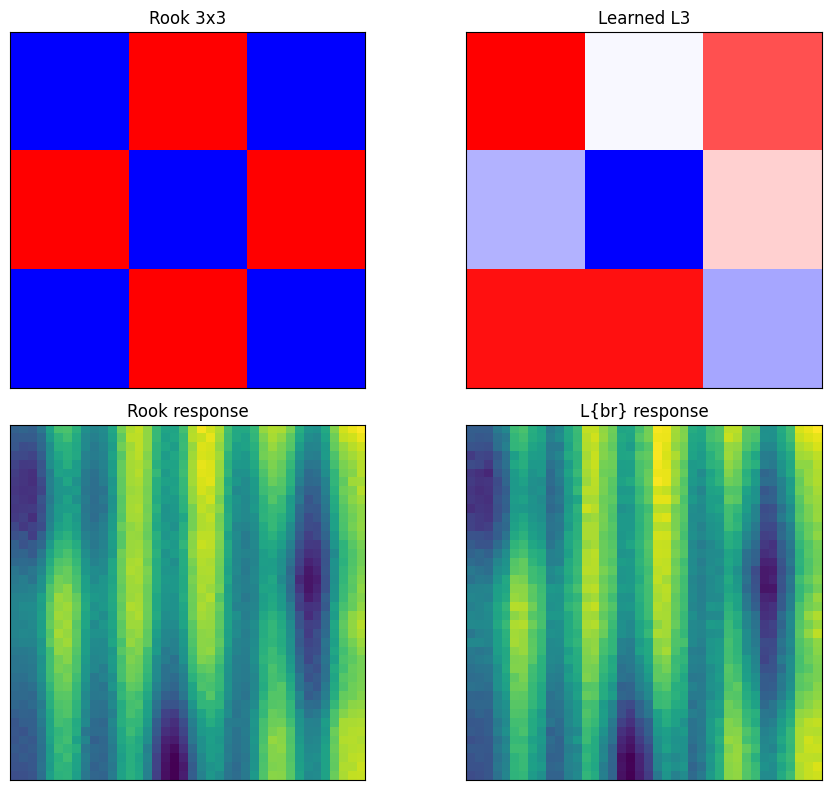

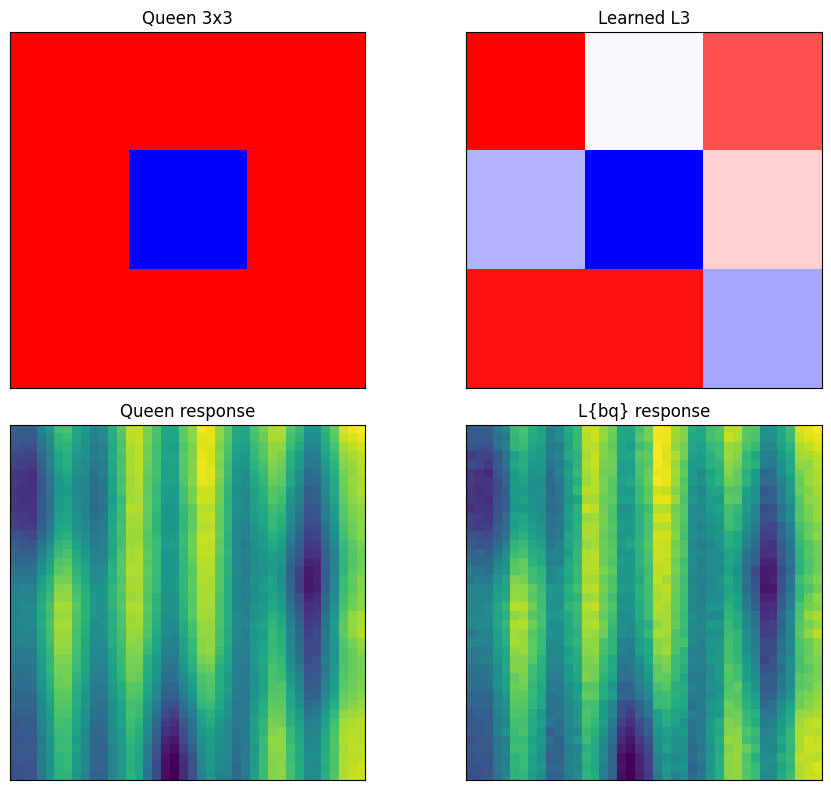

In [ ]:
rook3 = np.array([[0,1,0],[1,0,1],[0,1,0]], float); rook3/=rook3.sum()
queen3 = np.ones((3,3), float); queen3[1,1]=0; queen3/=queen3.sum()
def cosine_sim(A,B):
    a,b = A.reshape(-1), B.reshape(-1)
    na,nb = norm(a)+1e-12, norm(b)+1e-12
    return float((a@b)/(na*nb))
sims_rook = [cosine_sim(learned[i], rook3) for i in range(learned.shape[0])]
sims_queen= [cosine_sim(learned[i], queen3) for i in range(learned.shape[0])]
br, bq = int(np.argmax(sims_rook)), int(np.argmax(sims_queen))
print("Cosine sim to Rook:", np.round(sims_rook,3))
print("Cosine sim to Queen:", np.round(sims_queen,3))

from scipy.signal import convolve2d
def conv2(img, K):
    return convolve2d(img, K[::-1, ::-1], mode='same', boundary='symm')
resp_rook_map = conv2(yield_surface, rook3)
resp_queen_map= conv2(yield_surface, queen3)
resp_Lr_map   = conv2(yield_surface, learned[br])
resp_Lq_map   = conv2(yield_surface, learned[bq])

fig, axs = plt.subplots(2,2, figsize=(10,8))
axs[0,0].imshow(rook3, cmap='bwr'); axs[0,0].set_title('Rook 3x3')
axs[0,1].imshow(learned[br], cmap='bwr'); axs[0,1].set_title(f'Learned L{br}')
axs[1,0].imshow(resp_rook_map, origin='lower'); axs[1,0].set_title('Rook response')
axs[1,1].imshow(resp_Lr_map, origin='lower'); axs[1,1].set_title('L{br} response')
for ax in axs.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(2,2, figsize=(10,8))
axs[0,0].imshow(queen3, cmap='bwr'); axs[0,0].set_title('Queen 3x3')
axs[0,1].imshow(learned[bq], cmap='bwr'); axs[0,1].set_title(f'Learned L{bq}')
axs[1,0].imshow(resp_queen_map, origin='lower'); axs[1,0].set_title('Queen response')
axs[1,1].imshow(resp_Lq_map, origin='lower'); axs[1,1].set_title('L{bq} response')
for ax in axs.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [ ]:
def morans_I(resid, A):
    z = resid - resid.mean(); N=len(z)
    W = A.copy().astype(float)
    row_sums = np.array(W.sum(axis=1)).reshape(-1)
    row_sums[row_sums==0]=1
    W = sp.diags(1.0/row_sums) @ W
    zWz = float(z @ (W @ z)); zz = float(z @ z)
    return (N / W.count_nonzero()) * (zWz / (zz + 1e-12))

yvec = yield_surface.reshape(-1)
test_mask = ~mask

# CNN full-field proxy to align vectors for variance/MoranI
yhat_cnn_full = np.zeros_like(yvec)
# reconstruct CNN prediction at all locations by evaluating on all patches
with torch.no_grad():
    yhat_all = model(torch.from_numpy(X_img).to(device)).cpu().numpy().reshape(-1)
yhat_cnn_full = yhat_all

def metrics_all(y, yhat, test_mask):
    r = y[test_mask]-yhat[test_mask]
    mse = float(np.mean(r**2))
    mae = float(np.mean(np.abs(r)))
    ss_res = float(np.sum(r**2))
    ss_tot = float(np.sum((y[test_mask]-np.mean(y[test_mask]))**2))
    r2 = 1 - ss_res/ss_tot if ss_tot>0 else 0.0
    return mse, mae, r2

def variance_report(y, yhat, name):
    var_total = float(np.var(y[test_mask], ddof=1))
    mse, mae, r2 = metrics_all(y, yhat, test_mask)
    var_resid = float(np.var((y - yhat)[test_mask], ddof=1))
    var_expl  = max(var_total - var_resid, 0.0)
    I = morans_I((y - yhat), A_rook)
    return {'model':name,'MSE':mse,'MAE':mae,'R2':r2,'Var_total':var_total,'Var_explained':var_expl,'Var_residual':var_resid,'MoranI_residual':I}

rep_lap_rook  = variance_report(yvec, yhat_rook,  'Laplacian-Rook')
rep_lap_queen = variance_report(yvec, yhat_queen, 'Laplacian-Queen')
rep_r3        = variance_report(yvec, yhat_r3,    'Rook-3x3 (affine)')
rep_q3        = variance_report(yvec, yhat_q3,    'Queen-3x3 (affine)')
rep_cnn       = variance_report(yvec, yhat_cnn_full, 'CNN (local)')

import pandas as pd
df = pd.DataFrame([rep_lap_rook,rep_lap_queen,rep_r3,rep_q3,rep_cnn])
df[['model','MSE','MAE','R2','Var_total','Var_explained','Var_residual','MoranI_residual']]

,model,MSE,MAE,R2,Var_total,Var_explained,Var_residual,MoranI_residual
0,Laplacian-Rook,0.042785,0.189105,0.714637,0.150249,0.107391,0.042858,0.146753
1,Laplacian-Queen,0.068422,0.246046,0.543648,0.150249,0.081729,0.068520,0.176444
2,Rook-3x3 (affine),0.012388,0.091088,0.917374,0.150249,0.137845,0.012403,0.010447
3,Queen-3x3 (affine),0.025764,0.127264,0.828165,0.150249,0.124435,0.025813,0.039427
4,CNN (local),0.081138,0.268638,0.458839,0.150249,0.069967,0.080281,0.186407
